# 06 — XGBoost forecasting (Phase 3 · Step 1)

**Scope.** This notebook implements and evaluates the first Phase 3 model, XGBoost, on the 20 representative
items, using the same five expanding development folds, 28-day horizon and metrics as the completed Phase 2
item-level work, and compares it with Phase 2's Seasonal Naive, Croston and TSB.
**Phase 3 is not complete.** LSTM/GRU, Prophet, the final cross-model comparison, inventory decision support,
the dashboard and the one-time final-holdout evaluation are separate later steps and are *not* run here.

**Reused unchanged from Phase 2:** `split_final_holdout`, `generate_rolling_origins`, `run_backtest`,
`summarize_backtest`, `compute_metrics` (MAE, RMSE, zero-protected MAPE), `per_item_summary`,
`category_macro_average_summary`, the existing plot helpers, and the saved Phase 2 item-level artifacts (read only).
**New:** `src/models/xgboost_model.py`, plus two additive functions in `src/evaluation/item_level.py`
(`run_pooled_item_level_backtest`, `check_same_evaluation_grid`).

**Final holdout.** 2016-04-25 → 2016-05-22 is not read, fitted on, tuned on, selected on or reported anywhere in
this notebook. Section 10 proves it empirically instead of just stating it.

**Error scales.** Everything here is item level. Item-level MAE/RMSE are on a different (much smaller) scale than
the aggregate-series errors of Phase 2 Sections 1-11 and must not be compared with them.

**How results are described.** Every number quoted in a sentence below is computed by the cell that prints it;
the narrative markdown makes no claim about which model wins.

## 1. Setup and data

In [1]:
import sys
from pathlib import Path


def _find_project_root(start: Path) -> Path:
    """Walk up from `start` until a directory containing config.yaml is found (Jupyter's working
    directory differs between setups)."""
    for candidate in [start, *start.parents]:
        if (candidate / "config.yaml").exists():
            return candidate
    raise FileNotFoundError(
        f"Could not find config.yaml in any parent directory of '{start}'. Run this notebook from within the project."
    )


PROJECT_ROOT = _find_project_root(Path.cwd())
sys.path.insert(0, str(PROJECT_ROOT))

import dataclasses
import hashlib
import logging
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost

from src.data.splitter import split_final_holdout
from src.evaluation.backtesting import generate_rolling_origins
from src.evaluation.item_level import (
    category_macro_average_summary,
    check_same_evaluation_grid,
    item_development_series,
    per_item_summary,
    plot_category_comparison_by_model_color,
    plot_example_item_forecasts,
    run_item_level_backtests,
    run_pooled_item_level_backtest,
)
from src.models.baseline import SeasonalNaive
from src.models.croston import CrostonForecaster
from src.models.tsb import TSBForecaster
from src.models.xgboost_model import (
    PooledXGBoostForecaster,
    XGBoostConfig,
    XGBoostForecaster,
    build_training_frame,
    load_event_calendar,
)
from src.utils.config import load_config

%matplotlib inline
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
logging.getLogger().setLevel(logging.WARNING)  # keep INFO chatter out of the notebook; failures still log at ERROR

config = load_config()
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__, "| xgboost", xgboost.__version__)
print("Backtest settings:", config["backtest"])

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | xgboost 3.4.1
Backtest settings: {'holdout_days': 28, 'horizon': 28, 'n_folds': 5, 'season_length': 7}


In [2]:
processed_dir = PROJECT_ROOT / config["data"]["processed_dir"]
interim_dir = PROJECT_ROOT / config["data"]["interim_dir"]
forecasts_dir = PROJECT_ROOT / config["phase3"]["forecasts_dir"]
metrics_dir = PROJECT_ROOT / config["phase3"]["metrics_dir"]
reports_dir = PROJECT_ROOT / config["reports"]["phase3_dir"]
for directory in (forecasts_dir, metrics_dir, reports_dir):
    directory.mkdir(parents=True, exist_ok=True)

daily_sales_path = processed_dir / config["output"]["selected_items_daily_sales_filename"]
panel_path = interim_dir / config["output"]["panel_filename"]
for path in (daily_sales_path, panel_path):
    if not path.exists():
        raise FileNotFoundError(f"'{path}' not found. Run the Phase 1 pipeline first (see README).")

daily_sales = pd.read_parquet(daily_sales_path)
daily_sales["date"] = pd.to_datetime(daily_sales["date"])
item_ids = sorted(daily_sales["item_id"].unique())
assert len(item_ids) == 20, f"Expected 20 selected items, got {len(item_ids)}"
assert len(daily_sales) == 20 * 1941, f"Expected 38820 rows, got {len(daily_sales)}"

HOLDOUT_DAYS = config["backtest"]["holdout_days"]
HORIZON = config["backtest"]["horizon"]
N_FOLDS = config["backtest"]["n_folds"]
CATEGORY_ORDER = ["Smooth", "Intermittent", "Erratic", "Lumpy"]

# The development/holdout boundary comes from the same split function every Phase 2 step used.
date_frame = daily_sales[["date"]].drop_duplicates().sort_values("date").reset_index(drop=True)
split = split_final_holdout(date_frame, holdout_days=HOLDOUT_DAYS)
print(split.summary())
print(f"\nLoaded {len(daily_sales)} rows, {len(item_ids)} items.")
print("Items per demand class (Phase 1 labels, used only to group results):")
print(daily_sales.drop_duplicates("item_id")["demand_class"].value_counts().reindex(CATEGORY_ORDER).to_string())

# Calendar/event facts: only calendar columns, filtered to the development end WHILE reading the file.
xgb_cfg = XGBoostConfig.from_config(config)
event_calendar = load_event_calendar(panel_path, last_date=split.dev_end)
assert event_calendar.index.max() == split.dev_end and event_calendar.index.max() < split.test_start
print(f"\nEvent calendar: {len(event_calendar)} days, {event_calendar.index.min().date()} to {event_calendar.index.max().date()}")
print(event_calendar.sum().to_string())

development: 2011-01-29 -> 2016-04-24 (1913 days)
final test:  2016-04-25 -> 2016-05-22 (28 days)

Loaded 38820 rows, 20 items.
Items per demand class (Phase 1 labels, used only to group results):
demand_class
Smooth          5
Intermittent    5
Erratic         5
Lumpy           5



Event calendar: 1913 days, 2011-01-29 to 2016-04-24
snap_ca            630
event_cultural      38
event_national      51
event_religious     53
event_sporting      16
is_christmas         5


## 2. Features: definitions and availability

A forecast for day *t* is made at an **origin** *T < t* (the last training day). Every feature below must be
computable at *T*.

| Feature | Definition | Availability at the origin |
|---|---|---|
| `lag_1`, `lag_7`, `lag_14`, `lag_28` | the item's sales at *t−1, t−7, t−14, t−28* | observed history up to *T*; beyond *T* the model's **own earlier forecasts** (recursive forecasting), never unseen actuals |
| `roll_mean_7`, `roll_mean_14`, `roll_mean_28` | mean of the item's sales over *t−w … t−1* | same as lags; the window **ends the day before the target**, i.e. the series is shifted before it is averaged, so a row never contains its own target-day sales |
| `dayofweek`, `month`, `dayofmonth` | from the date | a calendar fact |
| `snap_ca`, `event_cultural`, `event_national`, `event_religious`, `event_sporting`, `is_christmas` | M5 calendar: SNAP day for California, event type of either event slot, and the Christmas closure flag | published in advance, identical for every item; only these calendar columns are read from the panel, and rows after the development end are dropped while reading |
| `item_id` (pooled model) | categorical item identity | static |
| `demand_class` (pooled model) | ADI/CV² class **recomputed from each fold's training window only** (`classify_series`) | see below |

**Not used.** `sell_price`: a price on a forecast date is only legitimate as a planned, known-in-advance covariate,
which the data cannot verify, and an absent weekly price in M5 also encodes "item not on sale". It is left for a
later step with an explicit availability assumption.

**Why `demand_class` is recomputed per fold.** The Phase 1 label in the parquet file was computed on all 1,941 days,
including every fold's forecast window and the final holdout (Phase 2 report, limitation L7). Using it as a model input
would leak future demand behaviour. The Phase 1 label is therefore used only to *group results*, exactly as in
Phase 2 Step 7; the model sees the fold-local class.

**Warm-up rows.** A training row needs 28 days of history, so the first 28 rows of every item are excluded from the
training matrix (they still serve as history for later rows). No lag or rolling value is imputed.

In [3]:
demo_item = daily_sales.loc[daily_sales["demand_class"] == "Smooth", "item_id"].iloc[0]
demo_series = item_development_series(daily_sales, demo_item, holdout_days=HOLDOUT_DAYS)
assert demo_series.index.max() == split.dev_end

origins = generate_rolling_origins(len(demo_series), horizon=HORIZON, n_folds=N_FOLDS)
demo_train = demo_series.iloc[: origins[0].train_end]
frame, n_dropped = build_training_frame({demo_item: demo_train}, xgb_cfg, event_calendar)
print(f"Demo item {demo_item}: fold-1 training window {demo_train.index[0].date()} to {demo_train.index[-1].date()} "
      f"({len(demo_train)} days) -> {len(frame)} training rows; {n_dropped} warm-up rows excluded")
display(frame.head(3))

# Hand-check the first training row against the definitions, straight from the raw series.
row = frame.iloc[0]
t = demo_train.index.get_loc(row["date"])
assert row["y"] == demo_train.iloc[t]
assert row["lag_1"] == demo_train.iloc[t - 1] and row["lag_7"] == demo_train.iloc[t - 7]
assert row["lag_14"] == demo_train.iloc[t - 14] and row["lag_28"] == demo_train.iloc[t - 28]
for w in (7, 14, 28):
    assert np.isclose(row[f"roll_mean_{w}"], demo_train.iloc[t - w : t].mean())   # t-w .. t-1: excludes day t
print("\nHand check passed: lags and rolling means equal the definitions, and the rolling windows exclude the target day.")

# Leakage probe: overwrite the target day's sales and rebuild; that row's features must not move.
probe = demo_train.copy()
probe.iloc[t] = 10_000.0
frame_probe, _ = build_training_frame({demo_item: probe}, xgb_cfg, event_calendar)
numeric = xgb_cfg.numeric_feature_names()
same_row = frame_probe["date"] == row["date"]
assert np.array_equal(frame.loc[frame["date"] == row["date"], numeric].to_numpy(), frame_probe.loc[same_row, numeric].to_numpy())
assert frame_probe.loc[same_row, "y"].iloc[0] == 10_000.0
print("Leakage probe passed: changing a day's own sales changes its target but none of its features.")

Demo item FOODS_3_067: fold-1 training window 2011-01-29 to 2015-12-06 (1773 days) -> 1745 training rows; 28 warm-up rows excluded


,item_id,date,y,lag_1,lag_7,lag_14,lag_28,roll_mean_7,roll_mean_14,roll_mean_28,dayofweek,month,dayofmonth,snap_ca,event_cultural,event_national,event_religious,event_sporting,is_christmas
0,FOODS_3_067,2011-02-26,0.0,10.0,5.0,9.0,0.0,5.714286,5.428571,4.821429,5,2,26,0,0,0,0,0,0
1,FOODS_3_067,2011-02-27,8.0,0.0,4.0,5.0,0.0,5.000000,4.785714,4.821429,6,2,27,0,0,0,0,0,0
2,FOODS_3_067,2011-02-28,4.0,8.0,3.0,2.0,1.0,5.571429,5.000000,5.107143,0,2,28,0,0,0,0,0,0



Hand check passed: lags and rolling means equal the definitions, and the rolling windows exclude the target day.
Leakage probe passed: changing a day's own sales changes its target but none of its features.


## 3. Model and training strategy

**Primary model — one pooled `XGBRegressor` across the 20 items, refit on every fold.** Each item has only about
1,750-1,900 daily training rows, and half of the 20 selected items (the Intermittent and Lumpy classes) are sparse, so a
per-item tree model has little to learn weekly and calendar structure from. Pooling lets the items share that structure,
with `item_id` and the fold-local `demand_class` as categorical inputs (`enable_categorical=True`).

**Secondary variants, declared before any result was examined** (not a hyper-parameter search):

* `XGBoost(per-item)` — the same features and settings fit separately per item. It runs through the *unmodified*
  Phase 2 `run_backtest` and is the empirical check on the pooling decision.
* `XGBoost(pooled,poisson)` — the same pooled model with the `count:poisson` objective, because sales are counts.

**One explanatory ablation, added after the primary results had been seen** (so it cannot be used to choose the primary
model): `XGBoost(pooled,no-events)` drops the SNAP/event/Christmas flags and keeps the date features.

**Fixed settings** (`config.yaml → xgboost`): 300 trees, learning rate 0.05, depth 6, `subsample`/`colsample_bytree` 0.8,
`random_state` 42, `n_jobs` 1 (single thread, so results do not depend on the number of cores). No early stopping, no search.

**Non-negative demand.** Every prediction is clipped at 0, *inside* the recursion (a negative value is never fed back
as a lag) and in the returned forecast, for every objective. A NaN or infinite prediction is never clipped or replaced:
it raises, and the fold is recorded as failed.

In [4]:
print("XGBoostConfig:")
for field in dataclasses.fields(xgb_cfg):
    print(f"  {field.name}: {getattr(xgb_cfg, field.name)}")
print("\nFeatures, pooled model (%d):" % len(xgb_cfg.feature_names(pooled=True)), xgb_cfg.feature_names(pooled=True))
print("Features, per-item model (%d):" % len(xgb_cfg.feature_names(pooled=False)))
print("\nResolved XGBRegressor parameters:", {k: v for k, v in xgb_cfg.regressor_params().items()})

XGBoostConfig:
  lags: (1, 7, 14, 28)
  rolling_mean_windows: (7, 14, 28)
  use_event_calendar: True
  objective: reg:squarederror
  n_estimators: 300
  learning_rate: 0.05
  max_depth: 6
  min_child_weight: 1.0
  subsample: 0.8
  colsample_bytree: 0.8
  reg_lambda: 1.0
  random_state: 42
  n_jobs: 1
  tree_method: hist

Features, pooled model (18): ['lag_1', 'lag_7', 'lag_14', 'lag_28', 'roll_mean_7', 'roll_mean_14', 'roll_mean_28', 'dayofweek', 'month', 'dayofmonth', 'snap_ca', 'event_cultural', 'event_national', 'event_religious', 'event_sporting', 'is_christmas', 'item_id', 'demand_class']
Features, per-item model (16):

Resolved XGBRegressor parameters: {'objective': 'reg:squarederror', 'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 6, 'min_child_weight': 1.0, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 1.0, 'random_state': 42, 'n_jobs': 1, 'tree_method': 'hist'}


## 4. Walk-forward protocol

The same five expanding folds as Phase 2: the last 5 x 28 = 140 development days are cut into five consecutive 28-day
forecast windows, and each fold's model is fitted only on the days before its window. The fold boundaries come from
`generate_rolling_origins` (the function `run_backtest` uses) and are checked below against the dates stored in the Phase 2
artifacts.

In [5]:
fold_table = pd.DataFrame(
    [
        {
            "fold": o.fold,
            "n_train_days": o.train_end,
            "train_start": demo_series.index[0].date(),
            "last_training_day (origin)": demo_series.index[o.train_end - 1].date(),
            "forecast_start": demo_series.index[o.test_start].date(),
            "forecast_end": demo_series.index[o.test_end - 1].date(),
        }
        for o in origins
    ]
)
display(fold_table)

p2 = config["phase2"]
baseline_long_path = PROJECT_ROOT / p2["forecasts_dir"] / p2["item_level_long_results_filename"]
baseline_fold_path = PROJECT_ROOT / p2["metrics_dir"] / p2["item_level_fold_summary_filename"]
baseline_item_path = PROJECT_ROOT / p2["metrics_dir"] / p2["item_level_per_item_summary_filename"]
baseline_category_path = PROJECT_ROOT / p2["metrics_dir"] / p2["item_level_category_summary_filename"]
phase2_paths = [baseline_long_path, baseline_fold_path, baseline_item_path, baseline_category_path]
for path in phase2_paths:
    if not path.exists():
        raise FileNotFoundError(f"Phase 2 artifact '{path}' not found; run notebook 04 (Section 12) first.")
phase2_hashes_before = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in phase2_paths}

saved_folds = (
    pd.read_csv(baseline_fold_path)[["fold", "forecast_start", "forecast_end"]].drop_duplicates().sort_values("fold").reset_index(drop=True)
)
mine = fold_table[["fold", "forecast_start", "forecast_end"]].astype({"forecast_start": str, "forecast_end": str})
assert saved_folds.astype(str).equals(mine.astype(str)), "Fold dates differ from the Phase 2 artifacts!"
assert origins[-1].test_end == len(demo_series) and demo_series.index[origins[-1].test_end - 1] == split.dev_end
print("Fold dates are identical to the Phase 2 item-level artifacts; the last fold ends on the last development day "
      f"({split.dev_end.date()}), the day before the final holdout starts ({split.test_start.date()}).")

,fold,n_train_days,train_start,last_training_day (origin),forecast_start,forecast_end
0,1,1773,2011-01-29,2015-12-06,2015-12-07,2016-01-03
1,2,1801,2011-01-29,2016-01-03,2016-01-04,2016-01-31
2,3,1829,2011-01-29,2016-01-31,2016-02-01,2016-02-28
3,4,1857,2011-01-29,2016-02-28,2016-02-29,2016-03-27
4,5,1885,2011-01-29,2016-03-27,2016-03-28,2016-04-24


Fold dates are identical to the Phase 2 item-level artifacts; the last fold ends on the last development day (2016-04-24), the day before the final holdout starts (2016-04-25).


## 5. Primary model: pooled XGBoost, five walk-forward folds

`run_pooled_item_level_backtest` fits **one** model per fold on every item's training prefix, forecasts all 20 items
28 days ahead recursively, and returns the same long and fold-summary tables as the Phase 2 item-level runner. A fit or
predict failure is recorded for the fold rather than aborting the run.

In [6]:
def make_pooled(cfg=xgb_cfg, name=None):
    return lambda: PooledXGBoostForecaster(cfg, event_calendar=event_calendar, name=name)


def run_pooled(cfg=xgb_cfg, name=None, data=daily_sales):
    return run_pooled_item_level_backtest(
        data, item_ids, make_pooled(cfg, name), horizon=HORIZON, n_folds=N_FOLDS, holdout_days=HOLDOUT_DAYS
    )


started = time.perf_counter()
primary = run_pooled()
primary_seconds = time.perf_counter() - started
PRIMARY = primary["long"]["model"].iloc[0]

n_expected_long = len(item_ids) * N_FOLDS * HORIZON
n_expected_folds = len(item_ids) * N_FOLDS
print(f"Model: {PRIMARY}   (wall time for all {N_FOLDS} folds: {primary_seconds:.1f}s)")
print(f"Long results table: {len(primary['long'])} rows (expected {n_expected_long})")
print(f"Fold summary table: {len(primary['fold_summary'])} rows (expected {n_expected_folds})")
assert len(primary["long"]) == n_expected_long and len(primary["fold_summary"]) == n_expected_folds

n_failed = int((~primary["fold_summary"]["success"]).sum())
print(f"Failed (item, fold) combinations: {n_failed}")
n_bad = int(primary["long"]["predicted"].isna().sum() + np.isinf(primary["long"]["predicted"]).sum() + (primary["long"]["predicted"] < 0).sum())
print(f"NaN / infinite / negative predictions in the saved forecasts: {n_bad}")
assert n_failed == 0 and n_bad == 0

diag_cols = ["fold", "success", "n_train_rows", "n_warmup_rows_dropped", "n_features", "fit_seconds", "n_warnings",
             "n_predictions", "n_predictions_clipped_at_zero", "min_raw_prediction", "max_prediction"]
display(primary["fold_diagnostics"][diag_cols])
print("Warnings raised while fitting:", int(primary["fold_diagnostics"]["n_warnings"].sum()))

Model: XGBoost(pooled)   (wall time for all 5 folds: 8.7s)
Long results table: 2800 rows (expected 2800)
Fold summary table: 100 rows (expected 100)
Failed (item, fold) combinations: 0
NaN / infinite / negative predictions in the saved forecasts: 0


,fold,success,n_train_rows,n_warmup_rows_dropped,n_features,fit_seconds,n_warnings,n_predictions,n_predictions_clipped_at_zero,min_raw_prediction,max_prediction
0,1,True,34900,560,18,1.387,0,560,41,-0.186957,14.724640
1,2,True,35460,560,18,1.174,0,560,11,-0.038474,17.386354
2,3,True,36020,560,18,1.184,0,560,7,-0.024427,16.123697
3,4,True,36580,560,18,1.356,0,560,2,-0.010216,23.060350
4,5,True,37140,560,18,1.278,0,560,11,-0.020088,15.197164


Warnings raised while fitting: 0


## 6. Secondary variants

Per-item XGBoost goes through the **unmodified** `run_item_level_backtests` / `run_backtest` (a `BaseForecaster`, one
model per item per fold). The Poisson and no-events variants reuse the pooled runner.

In [7]:
started = time.perf_counter()
per_item_run = run_item_level_backtests(
    daily_sales, item_ids, {"XGBoost(per-item)": lambda: XGBoostForecaster(xgb_cfg, event_calendar=event_calendar)},
    horizon=HORIZON, n_folds=N_FOLDS, holdout_days=HOLDOUT_DAYS,
)
per_item_seconds = time.perf_counter() - started
poisson_run = run_pooled(dataclasses.replace(xgb_cfg, objective="count:poisson"))
no_events_run = run_pooled(dataclasses.replace(xgb_cfg, use_event_calendar=False), name="XGBoost(pooled,no-events)")

variant_runs = {
    "XGBoost(per-item)": per_item_run,
    poisson_run["long"]["model"].iloc[0]: poisson_run,
    no_events_run["long"]["model"].iloc[0]: no_events_run,
}
for name, run in variant_runs.items():
    failed = int((~run["fold_summary"]["success"]).sum())
    print(f"{name:28s} long rows {len(run['long'])}, fold rows {len(run['fold_summary'])}, failed {failed}")
    assert len(run["long"]) == n_expected_long and len(run["fold_summary"]) == n_expected_folds and failed == 0
print(f"\nPer-item models: {per_item_seconds:.1f}s for {len(item_ids)} items x {N_FOLDS} folds; "
      f"pooled model: {primary_seconds:.1f}s for {N_FOLDS} folds (one fit per fold).")

xgb_long = pd.concat([primary["long"]] + [r["long"] for r in variant_runs.values()], ignore_index=True)
xgb_fold_summary = pd.concat([primary["fold_summary"]] + [r["fold_summary"] for r in variant_runs.values()], ignore_index=True)
XGB_MODELS = list(dict.fromkeys(xgb_long["model"]))
print("XGBoost models evaluated:", XGB_MODELS)

XGBoost(per-item)            long rows 2800, fold rows 100, failed 0
XGBoost(pooled,poisson)      long rows 2800, fold rows 100, failed 0
XGBoost(pooled,no-events)    long rows 2800, fold rows 100, failed 0

Per-item models: 58.6s for 20 items x 5 folds; pooled model: 8.7s for 5 folds (one fit per fold).
XGBoost models evaluated: ['XGBoost(pooled)', 'XGBoost(per-item)', 'XGBoost(pooled,poisson)', 'XGBoost(pooled,no-events)']


## 7. Phase 2 baselines on exactly the same cells

The baselines are the saved Phase 2 Step 7 results (read only). Two checks make the comparison safe: the baselines are
**re-run** here with the existing code and must reproduce the saved artifacts, and every XGBoost result must cover exactly
the same (item, fold, date) cells with the same actual values as the baselines.

In [8]:
baseline_factories = {
    "SeasonalNaive": lambda: SeasonalNaive(season_length=config["backtest"]["season_length"]),
    "Croston": lambda: CrostonForecaster(alpha=config["models"]["croston_alpha"]),
    "TSB": lambda: TSBForecaster(alpha=config["models"]["tsb_alpha"], beta=config["models"]["tsb_beta"]),
}
rerun = run_item_level_backtests(daily_sales, item_ids, baseline_factories, horizon=HORIZON, n_folds=N_FOLDS, holdout_days=HOLDOUT_DAYS)

baseline_long = pd.read_csv(baseline_long_path)
baseline_fold_summary = pd.read_csv(baseline_fold_path)
BASELINES = list(dict.fromkeys(baseline_long["model"]))
print("Baseline models in the Phase 2 artifacts:", BASELINES)

key = ["item_id", "model", "fold"]
saved = baseline_fold_summary.sort_values(key).reset_index(drop=True)
fresh = rerun["fold_summary"].sort_values(key).reset_index(drop=True)
assert saved[key].equals(fresh[key])
for metric in ["MAE", "RMSE", "MAPE"]:
    assert np.allclose(saved[metric].astype(float), fresh[metric].astype(float), rtol=1e-7, atol=1e-9, equal_nan=True), metric
max_diff = float(np.nanmax(np.abs(saved[["MAE", "RMSE"]].to_numpy(float) - fresh[["MAE", "RMSE"]].to_numpy(float))))
print(f"Re-running Seasonal Naive / Croston / TSB reproduces the saved Phase 2 fold metrics "
      f"(max absolute MAE/RMSE difference {max_diff:.2e}).")

saved_long = baseline_long.sort_values(key + ["date"]).reset_index(drop=True)
fresh_long = rerun["long"].assign(date=lambda d: d["date"].astype(str)).sort_values(key + ["date"]).reset_index(drop=True)
assert np.allclose(saved_long["predicted"], fresh_long["predicted"], rtol=1e-7, atol=1e-9)

grid = check_same_evaluation_grid(baseline_long, xgb_long)
print(f"\nSame evaluation grid for baselines and every XGBoost variant: {grid['n_cells']} (item, fold, date) cells, "
      f"{grid['n_items']} items, {grid['n_folds']} folds, max |actual difference| = {grid['max_abs_actual_diff']}.")

Baseline models in the Phase 2 artifacts: ['SeasonalNaive', 'Croston(alpha=0.1)', 'TSB(alpha=0.1,beta=0.1)']
Re-running Seasonal Naive / Croston / TSB reproduces the saved Phase 2 fold metrics (max absolute MAE/RMSE difference 3.55e-15).

Same evaluation grid for baselines and every XGBoost variant: 2800 (item, fold, date) cells, 20 items, 5 folds, max |actual difference| = 0.0.


## 8. Results

All errors are item level and are averaged exactly as in Phase 2 Step 7: per (item, model) over the five folds
(`per_item_summary`), then an **unweighted mean across items** within a demand category (`category_macro_average_summary`),
so no high-volume item dominates. MAPE is the existing zero-protected MAPE (zero-actual days are excluded and counted);
`MAPE_n_*_valid` says how many folds/items had a defined MAPE.

In [9]:
combined_fold_summary = pd.concat([baseline_fold_summary, xgb_fold_summary], ignore_index=True)
combined_per_item = per_item_summary(combined_fold_summary)
combined_category = category_macro_average_summary(combined_per_item)

MODEL_ORDER = BASELINES + XGB_MODELS
combined_per_item["model"] = pd.Categorical(combined_per_item["model"], categories=MODEL_ORDER, ordered=True)
combined_category["model"] = pd.Categorical(combined_category["model"], categories=MODEL_ORDER, ordered=True)
combined_category["demand_class"] = pd.Categorical(combined_category["demand_class"], categories=CATEGORY_ORDER, ordered=True)
combined_per_item = combined_per_item.sort_values(["demand_class", "item_id", "model"]).reset_index(drop=True)
combined_category = combined_category.sort_values(["demand_class", "model"]).reset_index(drop=True)

# Development-fold metrics of the primary model, one row per fold: mean over the 20 items.
fold_level = combined_fold_summary[combined_fold_summary["model"].isin(BASELINES + [PRIMARY])]
fold_macro_exact = fold_level.groupby(["model", "fold"], observed=True)[["MAE", "RMSE", "MAPE"]].mean()
fold_macro = fold_macro_exact.round(3)
print("Macro-average over the 20 items, per fold (each fold's 28-day window):")
display(fold_macro.unstack("model")["MAE"].reindex(columns=BASELINES + [PRIMARY]).rename_axis(columns="MAE"))
display(fold_macro.unstack("model")["RMSE"].reindex(columns=BASELINES + [PRIMARY]).rename_axis(columns="RMSE"))
display(fold_macro.unstack("model")["MAPE"].reindex(columns=BASELINES + [PRIMARY]).rename_axis(columns="MAPE (%)"))
n_mape = fold_level[fold_level["model"] == PRIMARY].groupby("fold")["MAPE"].count()
print("Items with a defined MAPE per fold (MAPE is undefined when a window's actuals are all zero):", n_mape.to_dict())

tsb_name = next(m for m in BASELINES if m.startswith("TSB"))
for metric in ["MAE", "RMSE"]:
    by_fold = fold_macro_exact.unstack("model")[metric]
    gap = by_fold[PRIMARY] - by_fold[tsb_name]          # exact; only the printed values are rounded
    print(f"{metric}: {PRIMARY} minus {tsb_name} per fold = {gap.round(3).to_dict()}; "
          f"{PRIMARY} is lower in {int((gap < 0).sum())} of {len(gap)} folds (mean gap {gap.mean():+.3f}, std {gap.std(ddof=1):.3f}).")

Macro-average over the 20 items, per fold (each fold's 28-day window):


MAE,SeasonalNaive,Croston(alpha=0.1),"TSB(alpha=0.1,beta=0.1)",XGBoost(pooled)
fold,,,,
1,2.075,3.152,1.653,1.674
2,2.414,2.192,1.915,1.853
3,2.052,1.946,1.755,1.717
4,2.318,1.986,1.923,2.014
5,2.854,2.623,2.525,2.640


RMSE,SeasonalNaive,Croston(alpha=0.1),"TSB(alpha=0.1,beta=0.1)",XGBoost(pooled)
fold,,,,
1,2.995,3.539,2.377,2.225
2,3.071,2.700,2.358,2.248
3,2.742,2.516,2.276,2.205
4,3.070,2.543,2.503,2.524
5,3.539,3.082,2.988,3.133


MAPE (%),SeasonalNaive,Croston(alpha=0.1),"TSB(alpha=0.1,beta=0.1)",XGBoost(pooled)
fold,,,,
1,90.144,74.524,70.541,64.898
2,96.271,71.531,69.252,74.606
3,72.342,59.475,56.992,64.510
4,80.627,62.668,63.623,69.738
5,72.676,58.124,59.063,60.602


Items with a defined MAPE per fold (MAPE is undefined when a window's actuals are all zero): {1: 18, 2: 19, 3: 18, 4: 19, 5: 19}
MAE: XGBoost(pooled) minus TSB(alpha=0.1,beta=0.1) per fold = {1: 0.021, 2: -0.062, 3: -0.038, 4: 0.091, 5: 0.115}; XGBoost(pooled) is lower in 2 of 5 folds (mean gap +0.026, std 0.078).
RMSE: XGBoost(pooled) minus TSB(alpha=0.1,beta=0.1) per fold = {1: -0.153, 2: -0.11, 3: -0.071, 4: 0.021, 5: 0.145}; XGBoost(pooled) is lower in 3 of 5 folds (mean gap -0.033, std 0.119).


In [10]:
overall = (
    combined_per_item.groupby("model", observed=True)
    .agg(n_items=("item_id", "nunique"), MAE=("MAE_mean", "mean"), RMSE=("RMSE_mean", "mean"),
         MAPE=("MAPE_mean", "mean"), MAPE_items_valid=("MAPE_n_folds_valid", lambda s: int((s > 0).sum())))
    .round(3)
)
print("All 20 items, macro-average of each item's 5-fold mean error:")
display(overall)

print("Category-level macro-averaged results (5 items per category):")
display(combined_category.round(3))

All 20 items, macro-average of each item's 5-fold mean error:


,n_items,MAE,RMSE,MAPE,MAPE_items_valid
model,,,,,
SeasonalNaive,20,2.342,3.083,83.518,20
Croston(alpha=0.1),20,2.380,2.876,64.882,20
"TSB(alpha=0.1,beta=0.1)",20,1.954,2.500,64.276,20
XGBoost(pooled),20,1.980,2.467,66.794,20
XGBoost(per-item),20,2.058,2.586,67.568,20
"XGBoost(pooled,poisson)",20,1.976,2.461,64.535,20
"XGBoost(pooled,no-events)",20,1.965,2.461,66.874,20


Category-level macro-averaged results (5 items per category):


,demand_class,model,n_items,MAE_macro_mean,RMSE_macro_mean,MAPE_macro_mean,MAPE_n_items_valid
0,Smooth,SeasonalNaive,5,2.940,3.872,87.268,5
1,Smooth,Croston(alpha=0.1),5,2.504,3.217,64.836,5
2,Smooth,"TSB(alpha=0.1,beta=0.1)",5,2.298,3.035,67.613,5
3,Smooth,XGBoost(pooled),5,2.144,2.812,66.489,5
4,Smooth,XGBoost(per-item),5,2.281,2.932,71.265,5
5,Smooth,"XGBoost(pooled,poisson)",5,2.165,2.828,67.142,5
6,Smooth,"XGBoost(pooled,no-events)",5,2.181,2.845,66.569,5
7,Intermittent,SeasonalNaive,5,1.103,1.549,77.801,5
8,Intermittent,Croston(alpha=0.1),5,1.032,1.318,58.047,5
9,Intermittent,"TSB(alpha=0.1,beta=0.1)",5,0.946,1.223,51.700,5


In [11]:
for metric in ["MAE_macro_mean", "RMSE_macro_mean", "MAPE_macro_mean"]:
    pivot = combined_category.pivot(index="demand_class", columns="model", values=metric).reindex(CATEGORY_ORDER)[MODEL_ORDER]
    print(f"\n{metric}")
    display(pivot.round(3))
    if metric != "MAPE_macro_mean":
        print(f"Lowest {metric.split('_')[0]} among the three Phase 2 baselines and {PRIMARY}:")
        four = pivot[BASELINES + [PRIMARY]]
        for cat in CATEGORY_ORDER:
            best = four.loc[cat].idxmin()
            vs_best_baseline = pivot.loc[cat, PRIMARY] / pivot.loc[cat, BASELINES].min() - 1
            print(f"  {cat:13s} {best:26s} ({PRIMARY} is {vs_best_baseline:+.1%} vs. the best baseline)")


MAE_macro_mean


model,SeasonalNaive,Croston(alpha=0.1),"TSB(alpha=0.1,beta=0.1)",XGBoost(pooled),XGBoost(per-item),"XGBoost(pooled,poisson)","XGBoost(pooled,no-events)"
demand_class,,,,,,,
Smooth,2.940,2.504,2.298,2.144,2.281,2.165,2.181
Intermittent,1.103,1.032,0.946,0.977,1.111,0.994,0.999
Erratic,4.039,4.390,3.388,3.520,3.373,3.446,3.413
Lumpy,1.289,1.594,1.185,1.277,1.468,1.299,1.269


Lowest MAE among the three Phase 2 baselines and XGBoost(pooled):
  Smooth        XGBoost(pooled)            (XGBoost(pooled) is -6.7% vs. the best baseline)
  Intermittent  TSB(alpha=0.1,beta=0.1)    (XGBoost(pooled) is +3.3% vs. the best baseline)
  Erratic       TSB(alpha=0.1,beta=0.1)    (XGBoost(pooled) is +3.9% vs. the best baseline)
  Lumpy         TSB(alpha=0.1,beta=0.1)    (XGBoost(pooled) is +7.7% vs. the best baseline)

RMSE_macro_mean


model,SeasonalNaive,Croston(alpha=0.1),"TSB(alpha=0.1,beta=0.1)",XGBoost(pooled),XGBoost(per-item),"XGBoost(pooled,poisson)","XGBoost(pooled,no-events)"
demand_class,,,,,,,
Smooth,3.872,3.217,3.035,2.812,2.932,2.828,2.845
Intermittent,1.549,1.318,1.223,1.276,1.409,1.260,1.289
Erratic,5.117,5.106,4.263,4.221,4.157,4.164,4.155
Lumpy,1.795,1.862,1.480,1.559,1.847,1.593,1.553


Lowest RMSE among the three Phase 2 baselines and XGBoost(pooled):
  Smooth        XGBoost(pooled)            (XGBoost(pooled) is -7.3% vs. the best baseline)
  Intermittent  TSB(alpha=0.1,beta=0.1)    (XGBoost(pooled) is +4.3% vs. the best baseline)
  Erratic       XGBoost(pooled)            (XGBoost(pooled) is -1.0% vs. the best baseline)
  Lumpy         TSB(alpha=0.1,beta=0.1)    (XGBoost(pooled) is +5.3% vs. the best baseline)

MAPE_macro_mean


model,SeasonalNaive,Croston(alpha=0.1),"TSB(alpha=0.1,beta=0.1)",XGBoost(pooled),XGBoost(per-item),"XGBoost(pooled,poisson)","XGBoost(pooled,no-events)"
demand_class,,,,,,,
Smooth,87.268,64.836,67.613,66.489,71.265,67.142,66.569
Intermittent,77.801,58.047,51.700,67.695,58.993,60.369,66.256
Erratic,78.123,71.400,67.833,64.104,63.085,63.320,65.821
Lumpy,90.879,65.245,69.958,68.887,76.929,67.309,68.850


### 8.1 Per item

Mean MAE over the item's five folds, one row per item; the lowest value among the three baselines and the primary model
is marked. This is the item-level table the category summaries above are averages of.

In [12]:
mae_by_item = combined_per_item.pivot(index=["demand_class", "item_id"], columns="model", values="MAE_mean")[MODEL_ORDER]
four = mae_by_item[BASELINES + [PRIMARY]]
mae_by_item.insert(0, "best_of_4", four.idxmin(axis=1).astype(str))
display(mae_by_item.round(3))

print("Items for which each model has the lowest MAE among the three baselines and the primary model:")
print(mae_by_item.groupby("demand_class", observed=True)["best_of_4"].value_counts().unstack(fill_value=0).reindex(CATEGORY_ORDER).to_string())
print()
print(mae_by_item["best_of_4"].value_counts().to_string())

model                                   best_of_4  SeasonalNaive  Croston(alpha=0.1)  TSB(alpha=0.1,beta=0.1)  XGBoost(pooled)  XGBoost(per-item)  XGBoost(pooled,poisson)  XGBoost(pooled,no-events)
demand_class item_id                                                                                                                                                                                 
Erratic      FOODS_3_076          XGBoost(pooled)          2.250               1.904                    1.903            1.771              1.888                    1.801                      1.814
             FOODS_3_313          XGBoost(pooled)          2.843               2.311                    2.314            2.116              2.195                    2.158                      2.160
             FOODS_3_319  TSB(alpha=0.1,beta=0.1)          5.871               6.226                    5.107            6.135              5.192                    5.864                      5.588
             FOODS_3_404  TSB(alpha=0.1,beta=0.1)          4.657               7.988                    4.005            4.217              4.287                    4.093                      4.107
             FOODS_3_702          XGBoost(pooled)          4.571               3.520                    3.609            3.363              3.304                    3.315                      3.395
Intermittent FOODS_3_042       Croston(alpha=0.1)          1.886               1.498                    1.501            1.607              1.613                    1.635                      1.638
             FOODS_3_206  TSB(alpha=0.1,beta=0.1)          0.836               1.226                    0.818            0.947              1.279                    0.958                      0.949
             FOODS_3_264          XGBoost(pooled)          0.743               0.688                    0.684            0.665              0.752                    0.658                      0.668
             FOODS_3_341          XGBoost(pooled)          0.871               0.759                    0.761            0.703              0.769                    0.707                      0.703
             FOODS_3_780  TSB(alpha=0.1,beta=0.1)          1.179               0.989                    0.963            0.964              1.143                    1.014                      1.035
Lumpy        FOODS_3_024  TSB(alpha=0.1,beta=0.1)          2.279               2.989                    2.143            2.403              2.655                    2.444                      2.387
             FOODS_3_271          XGBoost(pooled)          1.500               1.832                    1.400            1.327              1.432                    1.236                      1.352
             FOODS_3_422  TSB(alpha=0.1,beta=0.1)          1.300               1.245                    1.187            1.193              1.382                    1.176                      1.180
             FOODS_3_672  TSB(alpha=0.1,beta=0.1)          0.586               1.251                    0.540            0.812              1.092                    0.972                      0.773
             FOODS_3_761          XGBoost(pooled)          0.779               0.653                    0.657            0.650              0.778                    0.669                      0.655
Smooth       FOODS_3_067          XGBoost(pooled)          1.650               1.306                    1.312            1.289              1.312                    1.279                      1.296
             FOODS_3_230          XGBoost(pooled)          3.057               2.264                    2.265            2.084              2.303                    2.066                      2.096
             FOODS_3_263          XGBoost(pooled)          2.714               3.292                    2.257            2.207              2.256                    2.293                      2.257
             FOODS_3_330          XGBoos

Items for which each model has the lowest MAE among the three baselines and the primary model:
best_of_4     Croston(alpha=0.1)  TSB(alpha=0.1,beta=0.1)  XGBoost(pooled)
demand_class                                                              
Smooth                         0                        0                5
Intermittent                   1                        2                2
Erratic                        0                        2                3
Lumpy                          0                        3                2

best_of_4
XGBoost(pooled)            12
TSB(alpha=0.1,beta=0.1)     7
Croston(alpha=0.1)          1


### 8.2 Paired comparison at item-fold level

Number of the 100 (item, fold) windows in which the primary model has a **lower MAE** than each other model. Folds are
adjacent in time and items share the calendar, so these counts are descriptive and no significance test is attempted
(five folds; see limitation L1 of the Phase 2 report).

In [13]:
mae_pairs = combined_fold_summary.pivot_table(index=["item_id", "fold"], columns="model", values="MAE")
rows = []
for other in [m for m in MODEL_ORDER if m != PRIMARY]:
    valid = mae_pairs[[PRIMARY, other]].dropna()
    rows.append({"compared with": other, "windows": len(valid),
                 f"{PRIMARY} lower": int((valid[PRIMARY] < valid[other]).sum()),
                 "equal": int((valid[PRIMARY] == valid[other]).sum()),
                 f"{PRIMARY} higher": int((valid[PRIMARY] > valid[other]).sum())})
display(pd.DataFrame(rows).set_index("compared with"))

,windows,XGBoost(pooled) lower,equal,XGBoost(pooled) higher
compared with,,,,
SeasonalNaive,100,75,0,25
Croston(alpha=0.1),100,69,0,31
"TSB(alpha=0.1,beta=0.1)",100,60,0,40
XGBoost(per-item),100,65,0,35
"XGBoost(pooled,poisson)",100,54,0,46
"XGBoost(pooled,no-events)",100,52,0,48


### 8.3 Is pooling justified? (pooled vs. per-item XGBoost)

In [14]:
pooled_vs_item = combined_category.pivot(index="demand_class", columns="model", values="MAE_macro_mean").reindex(CATEGORY_ORDER)[[PRIMARY, "XGBoost(per-item)"]]
pooled_vs_item["pooled_minus_per_item"] = pooled_vs_item[PRIMARY] - pooled_vs_item["XGBoost(per-item)"]
display(pooled_vs_item.round(3))
n_cat_pooled_better = int((pooled_vs_item["pooled_minus_per_item"] < 0).sum())
item_pairs = mae_by_item[[PRIMARY, "XGBoost(per-item)"]]
n_items_pooled_better = int((item_pairs[PRIMARY] < item_pairs["XGBoost(per-item)"]).sum())
print(f"Pooled has the lower macro MAE in {n_cat_pooled_better} of 4 categories and the lower item MAE for "
      f"{n_items_pooled_better} of {len(item_pairs)} items.")
print(f"Compute: {primary_seconds:.1f}s for the pooled model (one fit per fold) vs. {per_item_seconds:.1f}s for per-item models "
      f"({len(item_ids)} fits per fold).")
print("This is a comparison of two pre-declared designs on five folds, not a selection step: the primary model was fixed in advance.")

model,XGBoost(pooled),XGBoost(per-item),pooled_minus_per_item
demand_class,,,
Smooth,2.144,2.281,-0.137
Intermittent,0.977,1.111,-0.134
Erratic,3.520,3.373,0.147
Lumpy,1.277,1.468,-0.191


Pooled has the lower macro MAE in 3 of 4 categories and the lower item MAE for 18 of 20 items.
Compute: 8.7s for the pooled model (one fit per fold) vs. 58.6s for per-item models (20 fits per fold).
This is a comparison of two pre-declared designs on five folds, not a selection step: the primary model was fixed in advance.


## 9. Figures

Saved reports/phase3/xgboost_category_mae_comparison.png


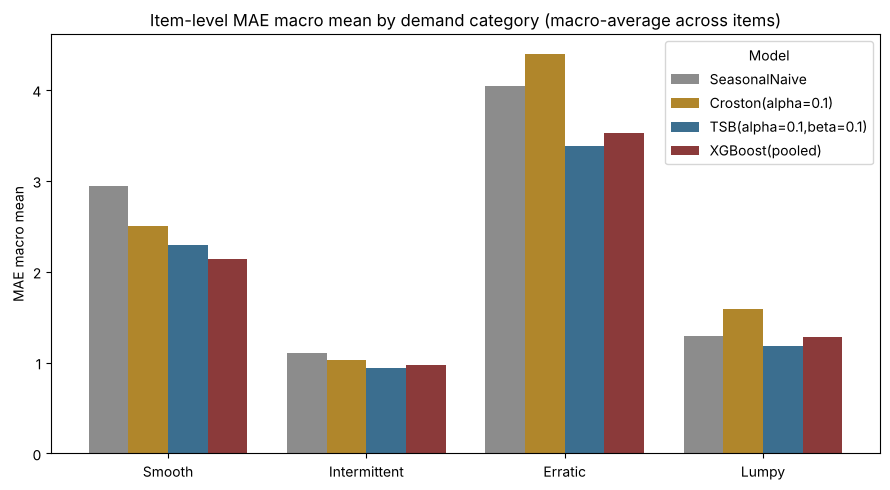

Saved reports/phase3/xgboost_category_rmse_comparison.png


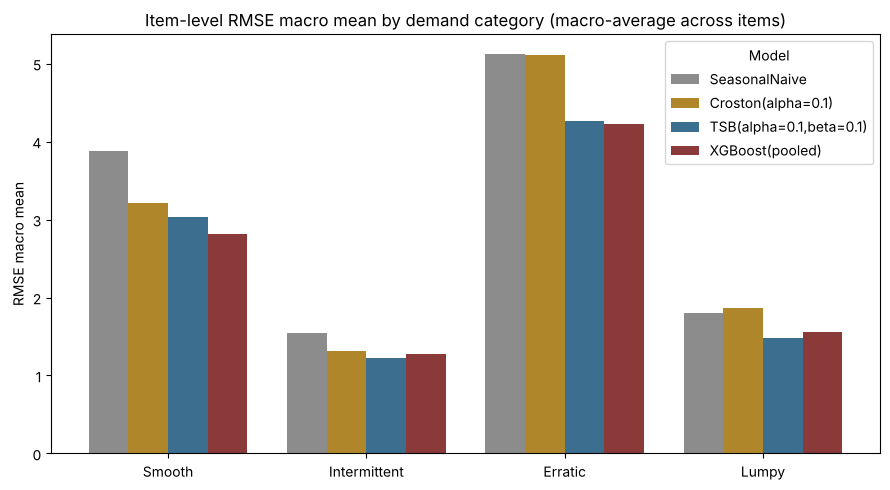

In [15]:
plot_models = BASELINES + [PRIMARY]
plot_summary = combined_category[combined_category["model"].isin(plot_models)].copy()
plot_summary["model"] = plot_summary["model"].astype(str)
plot_summary["demand_class"] = plot_summary["demand_class"].astype(str)
plot_summary = plot_summary.sort_values("model", key=lambda s: s.map({m: i for i, m in enumerate(plot_models)}), kind="stable")

p3 = config["phase3"]
mae_plot_path = reports_dir / p3["xgboost_category_mae_plot_filename"]
ax = plot_category_comparison_by_model_color(plot_summary, metric="MAE_macro_mean")
ax.figure.savefig(mae_plot_path, dpi=150)
print(f"Saved {mae_plot_path.relative_to(PROJECT_ROOT)}")
plt.show()

rmse_plot_path = reports_dir / p3["xgboost_category_rmse_plot_filename"]
ax = plot_category_comparison_by_model_color(plot_summary, metric="RMSE_macro_mean")
ax.figure.savefig(rmse_plot_path, dpi=150)
print(f"Saved {rmse_plot_path.relative_to(PROJECT_ROOT)}")
plt.show()

Example items (one per category, same rule as Phase 2): ['FOODS_3_067', 'FOODS_3_042', 'FOODS_3_076', 'FOODS_3_024']


Saved reports/phase3/xgboost_example_item_forecasts.png


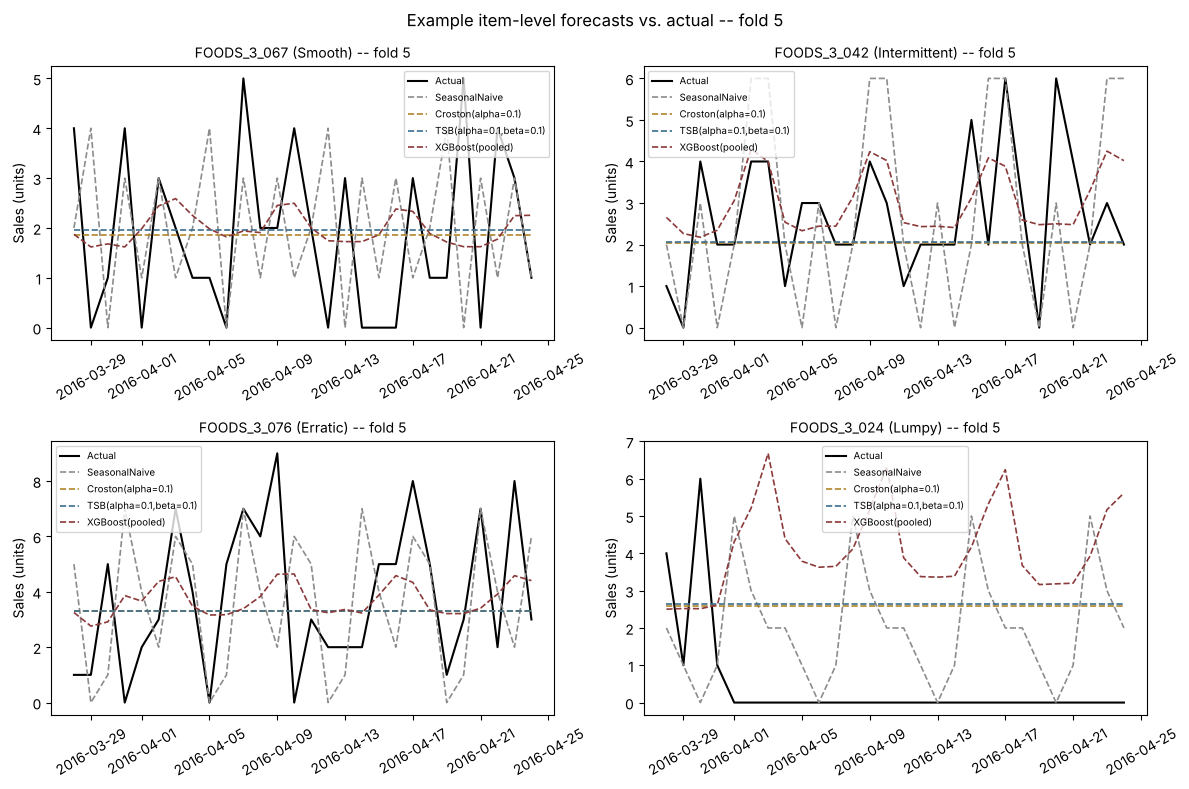

In [16]:
long_for_plots = pd.concat(
    [baseline_long, xgb_long[xgb_long["model"] == PRIMARY]], ignore_index=True
)
long_for_plots["date"] = pd.to_datetime(long_for_plots["date"])
example_items = (
    daily_sales.sort_values("item_id").groupby("demand_class", observed=True)["item_id"].first().reindex(CATEGORY_ORDER).tolist()
)
print("Example items (one per category, same rule as Phase 2):", example_items)
example_plot_path = reports_dir / p3["xgboost_example_forecasts_plot_filename"]
example_fig = plot_example_item_forecasts(long_for_plots, example_items, fold=N_FOLDS)
example_fig.savefig(example_plot_path, dpi=150)
print(f"Saved {example_plot_path.relative_to(PROJECT_ROOT)}")
plt.show()

,mean,min,max
feature,,,
roll_mean_7,0.362,0.348,0.382
roll_mean_14,0.222,0.205,0.244
lag_1,0.081,0.074,0.090
dayofweek,0.055,0.053,0.056
event_cultural,0.031,0.029,0.033
item_id,0.029,0.027,0.030
snap_ca,0.024,0.021,0.027
roll_mean_28,0.024,0.023,0.024
is_christmas,0.022,0.021,0.023


Saved reports/phase3/xgboost_feature_importance.png


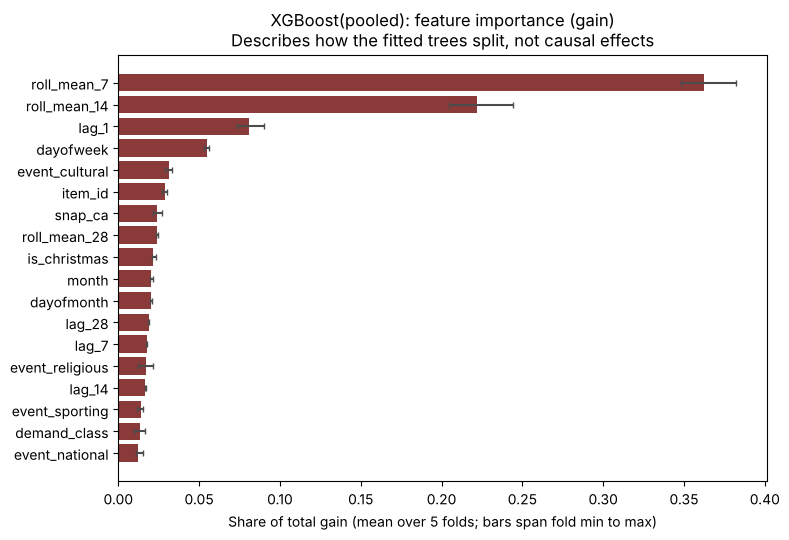

In [17]:
importance = primary["feature_importance"].copy()
importance["share"] = importance["gain"] / importance.groupby("fold")["gain"].transform("sum")
importance_summary = importance.groupby("feature")["share"].agg(["mean", "min", "max"]).sort_values("mean", ascending=False)
display(importance_summary.round(3))

importance_plot_path = reports_dir / p3["xgboost_feature_importance_plot_filename"]
fig, ax = plt.subplots(figsize=(8, 5.5))
order = importance_summary.sort_values("mean")
ax.barh(order.index, order["mean"], xerr=[order["mean"] - order["min"], order["max"] - order["mean"]], color="#8B3A3A", ecolor="#4C4C4C", capsize=2)
ax.set_xlabel("Share of total gain (mean over 5 folds; bars span fold min to max)")
ax.set_title(f"{PRIMARY}: feature importance (gain)\nDescribes how the fitted trees split, not causal effects")
fig.tight_layout()
fig.savefig(importance_plot_path, dpi=150)
print(f"Saved {importance_plot_path.relative_to(PROJECT_ROOT)}")
plt.show()

## 10. Diagnostics and failure cases

### 10.1 Zero-forecast yardstick (Phase 2 limitation L6)

On zero-inflated series MAE can reward low forecasts: an all-zero forecast scores the item's mean demand. The yardstick
below is **not a candidate model**; it only shows how far each model's MAE is from "forecast nothing".

In [18]:
zero_item = (
    primary["long"].groupby(["item_id", "demand_class", "fold"])["actual"].mean().rename("fold_zero_MAE").reset_index()
    .groupby(["item_id", "demand_class"])["fold_zero_MAE"].mean().rename("MAE_all_zero_forecast").reset_index()
)
yardstick = (
    combined_category.pivot(index="demand_class", columns="model", values="MAE_macro_mean").reindex(CATEGORY_ORDER)[BASELINES + [PRIMARY]]
    .join(zero_item.groupby("demand_class")["MAE_all_zero_forecast"].mean())
)
display(yardstick.round(3))

print("(category, model) pairs whose macro MAE is NOT below the all-zero yardstick:")
no_better = [(cat, model) for cat in CATEGORY_ORDER for model in BASELINES + [PRIMARY]
             if yardstick.loc[cat, model] >= yardstick.loc[cat, "MAE_all_zero_forecast"]]
for cat, model in no_better:
    print(f"  {cat:13s} {model:26s} {yardstick.loc[cat, model]:.3f} vs. all-zero {yardstick.loc[cat, 'MAE_all_zero_forecast']:.3f}")
if not no_better:
    print("  (none)")

with_zero = mae_by_item[[PRIMARY]].join(zero_item.set_index(["demand_class", "item_id"])["MAE_all_zero_forecast"])
worse_than_zero = with_zero[with_zero[PRIMARY] > with_zero["MAE_all_zero_forecast"]]
print(f"Items where {PRIMARY} has a higher MAE than an all-zero forecast: {len(worse_than_zero)} of {len(with_zero)}")
if len(worse_than_zero):
    display(worse_than_zero.round(3))

,SeasonalNaive,Croston(alpha=0.1),"TSB(alpha=0.1,beta=0.1)",XGBoost(pooled),MAE_all_zero_forecast
demand_class,,,,,
Smooth,2.940,2.504,2.298,2.144,4.077
Intermittent,1.103,1.032,0.946,0.977,1.043
Erratic,4.039,4.390,3.388,3.520,5.539
Lumpy,1.289,1.594,1.185,1.277,1.260


(category, model) pairs whose macro MAE is NOT below the all-zero yardstick:
  Intermittent  SeasonalNaive              1.103 vs. all-zero 1.043
  Lumpy         SeasonalNaive              1.289 vs. all-zero 1.260
  Lumpy         Croston(alpha=0.1)         1.594 vs. all-zero 1.260
  Lumpy         XGBoost(pooled)            1.277 vs. all-zero 1.260
Items where XGBoost(pooled) has a higher MAE than an all-zero forecast: 6 of 20


XGBoost(pooled)  MAE_all_zero_forecast
demand_class item_id                                            
Erratic      FOODS_3_319            6.135                  5.943
Intermittent FOODS_3_206            0.947                  0.636
             FOODS_3_341            0.703                  0.614
Lumpy        FOODS_3_024            2.403                  2.393
             FOODS_3_672            0.812                  0.514
             FOODS_3_761            0.650                  0.593

### 10.2 The 25 December closure in fold 1 (Phase 2 limitation L8)

CA_1 records zero sales on 25 December. Fold 1's window (2015-12-07 to 2016-01-03) contains it. The four earlier closures
(2011-2014) are in every model's training history. Only the XGBoost variants that use the event features also receive an
`is_christmas` flag for the forecast day (not `XGBoost(pooled,no-events)`); Seasonal Naive, Croston and TSB have no
calendar information. The column "closure_day_effect_on_MAE" is fold-1 MAE with the day minus fold-1 MAE without it, so a
negative value means the closure day made that model's fold-1 error *smaller*.

In [19]:
closure_day = pd.Timestamp("2015-12-25")
fold1 = pd.concat([baseline_long, xgb_long], ignore_index=True)
fold1["date"] = pd.to_datetime(fold1["date"])
fold1 = fold1[fold1["fold"] == 1]
assert closure_day in set(fold1["date"]) and fold1.loc[fold1["date"] == closure_day, "actual"].eq(0).all()


def fold1_macro_mae(table, exclude=None):
    table = table if exclude is None else table[table["date"] != exclude]
    per_item = table.assign(abs_err=(table["actual"] - table["predicted"]).abs()).groupby(["model", "item_id"])["abs_err"].mean()
    return per_item.groupby("model").mean()


closure = pd.DataFrame(
    {
        "mean_forecast_on_25_Dec (actual = 0)": fold1[fold1["date"] == closure_day].groupby("model")["predicted"].mean(),
        "fold1_macro_MAE_all_28_days": fold1_macro_mae(fold1),
        "fold1_macro_MAE_without_25_Dec": fold1_macro_mae(fold1, exclude=closure_day),
    }
).reindex(MODEL_ORDER)
closure["closure_day_effect_on_MAE"] = closure["fold1_macro_MAE_all_28_days"] - closure["fold1_macro_MAE_without_25_Dec"]
display(closure.round(3))

,mean_forecast_on_25_Dec (actual = 0),fold1_macro_MAE_all_28_days,fold1_macro_MAE_without_25_Dec,closure_day_effect_on_MAE
model,,,,
SeasonalNaive,1.450,2.075,2.098,-0.023
Croston(alpha=0.1),4.228,3.152,3.112,0.040
"TSB(alpha=0.1,beta=0.1)",2.155,1.653,1.634,0.019
XGBoost(pooled),0.549,1.674,1.716,-0.042
XGBoost(per-item),1.834,1.930,1.934,-0.004
"XGBoost(pooled,poisson)",0.105,1.641,1.698,-0.057
"XGBoost(pooled,no-events)",2.177,1.637,1.617,0.020


### 10.3 Non-negativity, fold-local demand classes, and warnings

In [20]:
clip = primary["fold_diagnostics"][["fold", "n_predictions", "n_predictions_clipped_at_zero", "min_raw_prediction"]]
display(clip)
total_clipped = int(clip["n_predictions_clipped_at_zero"].sum())
print(f"{PRIMARY}: {total_clipped} of {int(clip['n_predictions'].sum())} raw predictions were negative and were clipped to 0 "
      f"(most negative raw value {clip['min_raw_prediction'].min():.3f}).")
print(f"{poisson_run['long']['model'].iloc[0]} (log link) clipped {int(poisson_run['fold_diagnostics']['n_predictions_clipped_at_zero'].sum())}.")

classes = primary["fold_item_classes"].copy()
classes["same_as_phase1_label"] = classes["fold_local_class"].astype(str) == classes["phase1_class"].astype(str)
print("\nFold-local demand class (what the model saw) vs. the Phase 1 label (used only to group results):")
display(classes.groupby("fold")["same_as_phase1_label"].agg(agree="sum", of="count"))
differing = classes.loc[~classes["same_as_phase1_label"], ["fold", "item_id", "ADI", "CV2", "fold_local_class", "phase1_class"]]
if len(differing):
    display(differing.round(3))

all_warnings = int(primary["fold_diagnostics"]["n_warnings"].sum() + poisson_run["fold_diagnostics"]["n_warnings"].sum()
                   + no_events_run["fold_diagnostics"]["n_warnings"].sum())
print(f"\nWarnings captured while fitting the pooled models: {all_warnings}.")
print("Failed folds across every XGBoost variant:", int((~xgb_fold_summary["success"]).sum()))

,fold,n_predictions,n_predictions_clipped_at_zero,min_raw_prediction
0,1,560,41,-0.186957
1,2,560,11,-0.038474
2,3,560,7,-0.024427
3,4,560,2,-0.010216
4,5,560,11,-0.020088


XGBoost(pooled): 72 of 2800 raw predictions were negative and were clipped to 0 (most negative raw value -0.187).
XGBoost(pooled,poisson) (log link) clipped 0.

Fold-local demand class (what the model saw) vs. the Phase 1 label (used only to group results):


,agree,of
fold,,
1,20,20
2,20,20
3,20,20
4,20,20
5,20,20



Warnings captured while fitting the pooled models: 0.
Failed folds across every XGBoost variant: 0


### 10.4 Largest failures and gains (item-fold windows)

Where is the primary model furthest from the best of the three Phase 2 baselines? The windows below are ranked from all
100 (item, fold) results, not hand-picked. `zero_actual_days` counts days with zero actual demand in the 28-day window.

In [21]:
windows = combined_fold_summary.pivot_table(index=["item_id", "demand_class", "fold"], columns="model", values="MAE")
windows["best_baseline_MAE"] = windows[BASELINES].min(axis=1)
windows["best_baseline"] = windows[BASELINES].idxmin(axis=1)
windows["xgb_minus_best_baseline"] = windows[PRIMARY] - windows["best_baseline_MAE"]
window_stats = primary["long"].groupby(["item_id", "demand_class", "fold"]).agg(
    actual_mean=("actual", "mean"), forecast_mean=("predicted", "mean"),
    zero_actual_days=("actual", lambda s: int((s == 0).sum())),
)
windows = windows.join(window_stats)
show = ["actual_mean", "forecast_mean", "zero_actual_days", PRIMARY, "best_baseline", "best_baseline_MAE", "xgb_minus_best_baseline"]

n_better = int((windows["xgb_minus_best_baseline"] < 0).sum())
print(f"{PRIMARY} has a lower MAE than the best of the three baselines in {n_better} of {len(windows)} windows.")
worst = windows.sort_values("xgb_minus_best_baseline", ascending=False).head(8)
print("\nLargest shortfalls (XGBoost MAE minus best-baseline MAE):")
display(worst[show].round(3))
n_sparse = int((worst["zero_actual_days"] >= HORIZON // 2).sum())
print(f"Of these {len(worst)} windows, {n_sparse} have zero demand on at least half of the {HORIZON} days.")
print("\nLargest gains:")
display(windows.sort_values("xgb_minus_best_baseline").head(5)[show].round(3))

XGBoost(pooled) has a lower MAE than the best of the three baselines in 51 of 100 windows.

Largest shortfalls (XGBoost MAE minus best-baseline MAE):


actual_mean  forecast_mean  zero_actual_days  XGBoost(pooled)       best_baseline  best_baseline_MAE  xgb_minus_best_baseline
item_id     demand_class fold                                                                                                                               
FOODS_3_319 Erratic      4           8.214         16.121                 0            8.210  Croston(alpha=0.1)              4.353                    3.857
                         1           1.786          4.363                22            3.835       SeasonalNaive              1.786                    2.049
FOODS_3_024 Lumpy        5           0.429          4.111                24            4.038       SeasonalNaive              2.143                    1.895
FOODS_3_404 Erratic      5           1.071          9.662                24            8.886       SeasonalNaive              7.429                    1.457
FOODS_3_206 Intermittent 2           0.107          1.649                27            1.663       SeasonalNaive              0.964                    0.699
FOODS_3_404 Erratic      1           1.750          2.649                22            2.410       SeasonalNaive              1.750                    0.660
FOODS_3_672 Lumpy        3           0.000          0.556                28            0.556       SeasonalNaive              0.000                    0.556
                         5           1.321          2.406                12            1.793  Croston(alpha=0.1)              1.253                    0.540

Of these 8 windows, 6 have zero demand on at least half of the 28 days.

Largest gains:


actual_mean  forecast_mean  zero_actual_days  XGBoost(pooled)            best_baseline  best_baseline_MAE  xgb_minus_best_baseline
item_id     demand_class fold                                                                                                                                    
FOODS_3_348 Smooth       1           7.107          7.859                 2            3.653       Croston(alpha=0.1)              4.449                   -0.796
                         3           7.500          7.004                 1            2.395       Croston(alpha=0.1)              3.004                   -0.610
FOODS_3_313 Erratic      2           5.571          5.356                 0            1.819       Croston(alpha=0.1)              2.394                   -0.575
                         1           6.429          7.024                 2            3.006       Croston(alpha=0.1)              3.567                   -0.561
FOODS_3_404 Erratic      4           8.893          8.522                 1            3.125  TSB(alpha=0.1,beta=0.1)              3.682                   -0.558

### 10.5 Final-holdout separation, determinism and Phase 2 preservation

Three direct checks rather than assertions of intent:

1. **Perturbation of the holdout.** Every sales value after the development end is replaced by 1,000,000 and the whole
   primary run is repeated. If any holdout value reached a feature, a fit or a metric, the forecasts or actuals would change.
2. **Determinism.** The primary run is repeated with the same seed; forecasts must be bit-identical.
3. **Phase 2 artifacts.** The four Phase 2 item-level files are hashed before and after this notebook.

In [22]:
repeat = run_pooled()
assert np.array_equal(primary["long"]["predicted"].to_numpy(), repeat["long"]["predicted"].to_numpy())
print("Determinism: a second run with the same seed gives bit-identical forecasts.")

holdout_rows = daily_sales["date"] > split.dev_end
perturbed_sales = daily_sales.copy()
perturbed_sales.loc[holdout_rows, "sales"] = 1_000_000.0
perturbed = run_pooled(data=perturbed_sales)
assert int(holdout_rows.sum()) == len(item_ids) * HOLDOUT_DAYS
assert np.array_equal(primary["long"]["predicted"].to_numpy(), perturbed["long"]["predicted"].to_numpy())
assert np.array_equal(primary["long"]["actual"].to_numpy(), perturbed["long"]["actual"].to_numpy())
print(f"Holdout perturbation: replacing all {int(holdout_rows.sum())} holdout sales values by 1,000,000 changes no forecast and no actual.")

max_date_long = pd.to_datetime(xgb_long["date"]).max()
max_forecast_end = pd.to_datetime(xgb_fold_summary["forecast_end"]).max()
print(f"\nFinal holdout starts: {split.test_start.date()} (from the split above, not retyped here)")
print(f"Latest date in any XGBoost long results table: {max_date_long.date()}")
print(f"Latest forecast_end in any XGBoost fold summary: {max_forecast_end.date()}")
print(f"Latest date in the event calendar that was loaded: {event_calendar.index.max().date()}")
assert max_date_long < split.test_start and max_forecast_end < split.test_start and event_calendar.index.max() < split.test_start
print("\nConfirmed: no date on or after the final holdout start was used anywhere in this notebook.")

phase2_hashes_after = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in phase2_paths}
assert phase2_hashes_before == phase2_hashes_after
print("Confirmed: the four Phase 2 item-level artifacts are byte-for-byte unchanged by this notebook.")

Determinism: a second run with the same seed gives bit-identical forecasts.


Holdout perturbation: replacing all 560 holdout sales values by 1,000,000 changes no forecast and no actual.

Final holdout starts: 2016-04-25 (from the split above, not retyped here)
Latest date in any XGBoost long results table: 2016-04-24
Latest forecast_end in any XGBoost fold summary: 2016-04-24
Latest date in the event calendar that was loaded: 2016-04-24

Confirmed: no date on or after the final holdout start was used anywhere in this notebook.
Confirmed: the four Phase 2 item-level artifacts are byte-for-byte unchanged by this notebook.


## 11. Save outputs

New files only, in the existing artifact folders (`artifacts/forecasts`, `artifacts/metrics`, both git-ignored like all
Phase 2 artifacts) and in `reports/phase3/` for the figures. Phase 2 file names are never reused.

In [23]:
xgb_per_item = per_item_summary(xgb_fold_summary)
xgb_category = category_macro_average_summary(xgb_per_item)

outputs = {
    forecasts_dir / p3["xgboost_long_results_filename"]: xgb_long,
    metrics_dir / p3["xgboost_fold_summary_filename"]: xgb_fold_summary,
    metrics_dir / p3["xgboost_per_item_summary_filename"]: xgb_per_item,
    metrics_dir / p3["xgboost_category_summary_filename"]: xgb_category,
    metrics_dir / p3["xgboost_comparison_per_item_filename"]: combined_per_item,
    metrics_dir / p3["xgboost_comparison_category_filename"]: combined_category,
    metrics_dir / p3["xgboost_fold_diagnostics_filename"]: pd.concat(
        [primary["fold_diagnostics"], poisson_run["fold_diagnostics"], no_events_run["fold_diagnostics"]], ignore_index=True
    ),
    metrics_dir / p3["xgboost_fold_item_classes_filename"]: primary["fold_item_classes"],
    metrics_dir / p3["xgboost_feature_importance_filename"]: primary["feature_importance"],
}
phase2_names = {p.name for p in phase2_paths}
for path, table in outputs.items():
    assert path.name not in phase2_names, f"{path.name} would overwrite a Phase 2 artifact"
    table.to_csv(path, index=False)
    print(f"Saved {path.relative_to(PROJECT_ROOT)} ({len(table)} rows, {path.stat().st_size:,} bytes)")
print("\nPer-item XGBoost folds are not in the diagnostics file (they go through the unmodified run_backtest); "
      "their success/error status is in the fold summary.")

Saved artifacts/forecasts/xgboost_item_level_backtest_long.csv (11200 rows, 940,298 bytes)
Saved artifacts/metrics/xgboost_item_level_fold_summary.csv (400 rows, 52,988 bytes)
Saved artifacts/metrics/xgboost_item_level_per_item_summary.csv (80 rows, 8,390 bytes)
Saved artifacts/metrics/xgboost_item_level_category_macro_avg_summary.csv (16 rows, 1,522 bytes)
Saved artifacts/metrics/xgboost_vs_baselines_per_item_summary.csv (140 rows, 14,392 bytes)
Saved artifacts/metrics/xgboost_vs_baselines_category_macro_avg_summary.csv (28 rows, 2,558 bytes)
Saved artifacts/metrics/xgboost_fold_diagnostics.csv (15 rows, 5,880 bytes)
Saved artifacts/metrics/xgboost_fold_local_demand_classes.csv (100 rows, 7,414 bytes)
Saved artifacts/metrics/xgboost_feature_importance.csv (90 rows, 2,784 bytes)

Per-item XGBoost folds are not in the diagnostics file (they go through the unmodified run_backtest); their success/error status is in the fold summary.


## 12. Summary

In [24]:
print("Phase 3 Step 1 summary -- XGBoost on the 20 selected items (development folds only)\n")
print(f"Items: {len(item_ids)} (5 per demand class). Folds: {N_FOLDS} expanding, horizon {HORIZON} days, same dates as Phase 2.")
print(f"Primary model: {PRIMARY}; secondary variants: {[m for m in XGB_MODELS if m != PRIMARY]}")
print(f"(item, fold) combinations per model: {n_expected_folds}; failed across all XGBoost variants: {int((~xgb_fold_summary['success']).sum())}")

print("\nMacro-averaged MAE by category:")
print(combined_category.pivot(index="demand_class", columns="model", values="MAE_macro_mean").reindex(CATEGORY_ORDER)[BASELINES + [PRIMARY]].round(3).to_string())
best = combined_category.pivot(index="demand_class", columns="model", values="MAE_macro_mean").reindex(CATEGORY_ORDER)[BASELINES + [PRIMARY]].idxmin(axis=1)
print("\nLowest macro-averaged MAE per category (3 Phase 2 baselines + primary XGBoost, 20 items, 5 folds):")
for cat in CATEGORY_ORDER:
    print(f"  {cat:13s} {best[cat]}")
print("\nThat describes these four methods on these 20 items and five development folds only. It is not a final ranking: "
      "no significance test was run, the final holdout was not used, and the remaining Phase 3 models are not yet in the comparison.")
print("Item-level errors are not on the same scale as the aggregate-series errors in Phase 2 Sections 1-11.")
print(f"Final holdout ({split.test_start.date()} to {split.test_end.date()}) was NOT used anywhere in this notebook -- confirmed in Section 10.5.")
print("Phase 3 is NOT complete: LSTM/GRU, Prophet, the final comparison, inventory decision support and the dashboard are not implemented here.")

Phase 3 Step 1 summary -- XGBoost on the 20 selected items (development folds only)

Items: 20 (5 per demand class). Folds: 5 expanding, horizon 28 days, same dates as Phase 2.
Primary model: XGBoost(pooled); secondary variants: ['XGBoost(per-item)', 'XGBoost(pooled,poisson)', 'XGBoost(pooled,no-events)']
(item, fold) combinations per model: 100; failed across all XGBoost variants: 0

Macro-averaged MAE by category:
model         SeasonalNaive  Croston(alpha=0.1)  TSB(alpha=0.1,beta=0.1)  XGBoost(pooled)
demand_class                                                                             
Smooth                2.940               2.504                    2.298            2.144
Intermittent          1.103               1.032                    0.946            0.977
Erratic               4.039               4.390                    3.388            3.520
Lumpy                 1.289               1.594                    1.185            1.277

Lowest macro-averaged MAE per category 

## Limitations (Step 1)

* **Different information sets.** The baselines see only each item's own history; the XGBoost models also see calendar,
  SNAP and event flags and (when pooled) other items' histories. Differences between them mix model class and information.
  `XGBoost(pooled,no-events)` shows how much of the pooled model's result depends on the event flags.
* **Five folds, 20 items, one store and department.** No significance test; fold-to-fold variation can be as large as
  gaps between models. Nothing here generalises beyond CA_1/FOODS_3.
* **Fixed, untuned settings.** The hyper-parameters are a documented starting point, not an optimum. Tuning, if any, belongs
  inside training windows in a later step.
* **Recursive forecasts** feed on their own predictions, which are expected values and smoother than real sales; errors can
  compound over 28 days. Direct multi-horizon training is an alternative not tried here.
* **MAE on zero-inflated series** can reward low forecasts (L6); MAPE ignores zero-demand days and is noisy for low-volume items.
  No inventory-relevant measure (service level, stock-out vs holding cost) is computed yet.
* **`sell_price` is not used** (availability at the target date cannot be verified from this dataset).
* **Floating-point reproducibility** is exact on one machine and library version; another operating system, CPU or XGBoost
  version can differ in the last digits, which this notebook does not assert on.

## Reproduce

From the project root: `python -m pytest tests/models/test_xgboost_model.py tests/evaluation/test_item_level_pooled.py`,
then run this notebook top to bottom (or `python -m pytest tests/notebooks/test_xgboost_notebook.py`). Exact commands,
including Windows PowerShell, are in `reports/phase3/XGBoost_Step1_Report.md`.